# Vision Transformer (ViT) from Scratch with PyTorch


## 1. Imports and reproducibility

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.optim import Adam
from torch.nn import CrossEntropyLoss
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
from tqdm.auto import tqdm, trange

np.random.seed(0)
torch.manual_seed(0)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(0)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

Using device: cpu


## 2. Load the MNIST dataset

PyTorch downloads MNIST automatically. No Kaggle account or manual dataset download is needed.

In [2]:
transform = ToTensor()
train_set = MNIST(root='./datasets', train=True, download=True, transform=transform)
test_set = MNIST(root='./datasets', train=False, download=True, transform=transform)

train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
test_loader = DataLoader(test_set, batch_size=128, shuffle=False)

print('Training images:', len(train_set))
print('Test images:', len(test_set))

100%|██████████| 9.91M/9.91M [00:00<00:00, 38.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.20MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 8.87MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.9MB/s]

Training images: 60000
Test images: 10000


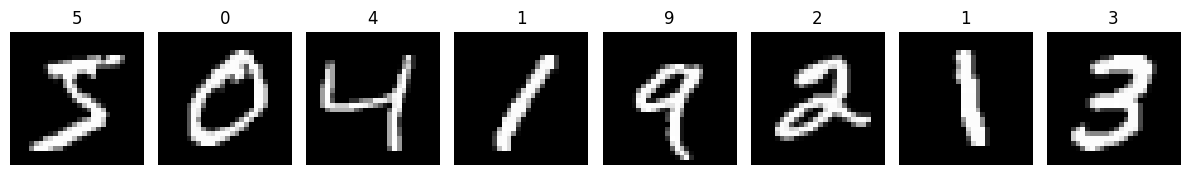

In [3]:
# Display a few training examples
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    image, label = train_set[i]
    ax.imshow(image.squeeze(), cmap='gray')
    ax.set_title(str(label))
    ax.axis('off')
plt.tight_layout()
plt.show()

## 3. Split each image into patches

MNIST images are 28 × 28 pixels. With `n_patches=7`, each image becomes a 7 × 7 grid: 49 patches, each 4 × 4 pixels. Each patch is flattened into a vector of length 16.

In [4]:
def patchify(images, n_patches):
    n, c, h, w = images.shape
    assert h == w, 'Only square images are supported.'
    assert h % n_patches == 0, 'Image size must be divisible by n_patches.'

    patch_size = h // n_patches
    patches = torch.zeros(
        n, n_patches * n_patches, c * patch_size * patch_size,
        device=images.device, dtype=images.dtype
    )

    for image_idx in range(n):
        patch_idx = 0
        for i in range(n_patches):
            for j in range(n_patches):
                patch = images[
                    image_idx, :,
                    i * patch_size:(i + 1) * patch_size,
                    j * patch_size:(j + 1) * patch_size
                ]
                patches[image_idx, patch_idx] = patch.reshape(-1)
                patch_idx += 1
    return patches

sample_images, _ = next(iter(train_loader))
sample_patches = patchify(sample_images[:7], n_patches=7)
print('Input shape:', sample_images[:7].shape)
print('Patches shape:', sample_patches.shape)  # (7, 49, 16)

Input shape: torch.Size([7, 1, 28, 28])
Patches shape: torch.Size([7, 49, 16])


## 4. Positional embeddings

The positional embedding gives each patch information about its position in the image. This implementation uses fixed sinusoidal embeddings.

In [5]:
def get_positional_embeddings(sequence_length, hidden_d):
    positions = torch.arange(sequence_length, dtype=torch.float32).unsqueeze(1)
    dimensions = torch.arange(hidden_d, dtype=torch.float32).unsqueeze(0)
    angles = positions / (10000 ** (2 * torch.floor(dimensions / 2) / hidden_d))
    embeddings = torch.zeros(sequence_length, hidden_d)
    embeddings[:, 0::2] = torch.sin(angles[:, 0::2])
    embeddings[:, 1::2] = torch.cos(angles[:, 1::2])
    return embeddings

## 5. Multi-head self-attention

For each token, attention computes query, key, and value vectors. The attention weights determine how much information each token receives from the other tokens.

In [6]:
class MyMSA(nn.Module):
    def __init__(self, hidden_d, n_heads=2):
        super().__init__()
        assert hidden_d % n_heads == 0, 'hidden_d must be divisible by n_heads.'
        self.hidden_d = hidden_d
        self.n_heads = n_heads
        self.d_head = hidden_d // n_heads

        self.q_mappings = nn.ModuleList([
            nn.Linear(self.d_head, self.d_head) for _ in range(n_heads)
        ])
        self.k_mappings = nn.ModuleList([
            nn.Linear(self.d_head, self.d_head) for _ in range(n_heads)
        ])
        self.v_mappings = nn.ModuleList([
            nn.Linear(self.d_head, self.d_head) for _ in range(n_heads)
        ])
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, sequences):
        # sequences: (batch, sequence_length, hidden_d)
        batch_results = []
        for sequence in sequences:
            head_results = []
            for head in range(self.n_heads):
                start = head * self.d_head
                end = (head + 1) * self.d_head
                seq = sequence[:, start:end]

                q = self.q_mappings[head](seq)
                k = self.k_mappings[head](seq)
                v = self.v_mappings[head](seq)

                attention = self.softmax(q @ k.T / math.sqrt(self.d_head))
                head_results.append(attention @ v)

            batch_results.append(torch.cat(head_results, dim=-1))
        return torch.stack(batch_results)

## 6. Transformer encoder block

Each block applies layer normalization, self-attention, and an MLP. Residual connections help preserve information across these operations.

In [7]:
class MyViTBlock(nn.Module):
    def __init__(self, hidden_d, n_heads, mlp_ratio=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(hidden_d)
        self.mhsa = MyMSA(hidden_d, n_heads)
        self.norm2 = nn.LayerNorm(hidden_d)
        self.mlp = nn.Sequential(
            nn.Linear(hidden_d, mlp_ratio * hidden_d),
            nn.GELU(),
            nn.Linear(mlp_ratio * hidden_d, hidden_d)
        )

    def forward(self, x):
        x = x + self.mhsa(self.norm1(x))
        x = x + self.mlp(self.norm2(x))
        return x

# Quick shape test
test_block = MyViTBlock(hidden_d=8, n_heads=2)
print('Encoder block output:', test_block(torch.randn(7, 50, 8)).shape)

Encoder block output: torch.Size([7, 50, 8])


## 7. Complete Vision Transformer model

The model adds a learnable classification token, adds positional embeddings, processes tokens through encoder blocks, then classifies using the final class token.

In [8]:
class MyViT(nn.Module):
    def __init__(self, chw=(1, 28, 28), n_patches=7, n_blocks=2,
                 hidden_d=8, n_heads=2, out_d=10):
        super().__init__()
        self.chw = chw
        self.n_patches = n_patches
        self.hidden_d = hidden_d

        assert chw[1] % n_patches == 0
        assert chw[2] % n_patches == 0
        patch_h = chw[1] // n_patches
        patch_w = chw[2] // n_patches
        self.input_d = chw[0] * patch_h * patch_w

        self.linear_mapper = nn.Linear(self.input_d, hidden_d)
        self.class_token = nn.Parameter(torch.randn(1, hidden_d))
        self.register_buffer(
            'positional_embeddings',
            get_positional_embeddings(n_patches * n_patches + 1, hidden_d),
            persistent=False
        )
        self.blocks = nn.ModuleList([
            MyViTBlock(hidden_d, n_heads) for _ in range(n_blocks)
        ])
        self.mlp = nn.Linear(hidden_d, out_d)

    def forward(self, images):
        batch_size = images.shape[0]
        patches = patchify(images, self.n_patches)
        tokens = self.linear_mapper(patches)
        class_tokens = self.class_token.expand(batch_size, 1, -1)
        tokens = torch.cat((class_tokens, tokens), dim=1)
        tokens = tokens + self.positional_embeddings.unsqueeze(0)

        for block in self.blocks:
            tokens = block(tokens)

        class_token_final = tokens[:, 0]
        return self.mlp(class_token_final)

model = MyViT((1, 28, 28), n_patches=7, n_blocks=2,
              hidden_d=8, n_heads=2, out_d=10).to(device)
dummy_output = model(torch.randn(4, 1, 28, 28, device=device))
print('Model output shape:', dummy_output.shape)  # (4, 10)

Model output shape: torch.Size([4, 10])


## 8. Train the model

The loss is cross-entropy because this is a 10-class classification task. The defaults below follow the small example in the guide.

In [9]:
N_EPOCHS = 5
LR = 0.005

optimizer = Adam(model.parameters(), lr=LR)
criterion = CrossEntropyLoss()
train_losses = []

for epoch in trange(N_EPOCHS, desc='Training'):
    model.train()
    running_loss = 0.0

    for x, y in tqdm(train_loader, desc=f'Epoch {epoch + 1}', leave=False):
        x, y = x.to(device), y.to(device)
        y_hat = model(x)
        loss = criterion(y_hat, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    train_losses.append(epoch_loss)
    print(f'Epoch {epoch + 1}/{N_EPOCHS} - loss: {epoch_loss:.4f}')

Training:   0%|          | 0/5 [00:00<?, ?it/s]

Epoch 1:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 1/5 - loss: 1.6163


Epoch 2:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 2/5 - loss: 0.8438


...

Epoch 3/5 - loss: 0.6120


Epoch 4:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 4/5 - loss: 0.5248


Epoch 5:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 5/5 - loss: 0.4725


## 9. Plot training loss

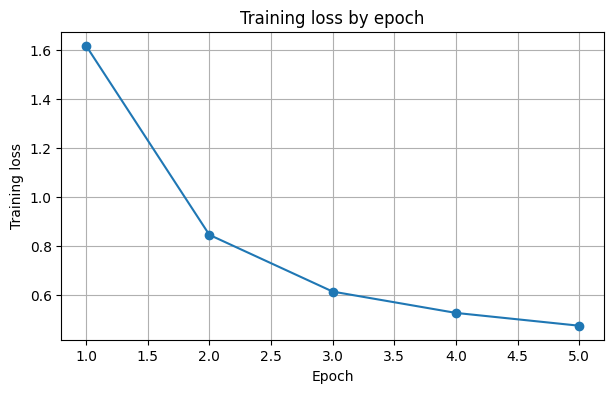

In [10]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, N_EPOCHS + 1), train_losses, marker='o')
plt.xlabel('Epoch')
plt.ylabel('Training loss')
plt.title('Training loss by epoch')
plt.grid(True)
plt.show()

## 10. Evaluate on the test set

In [11]:
model.eval()
correct = 0
total = 0
test_loss_sum = 0.0

with torch.no_grad():
    for x, y in tqdm(test_loader, desc='Testing'):
        x, y = x.to(device), y.to(device)
        y_hat = model(x)
        loss = criterion(y_hat, y)
        test_loss_sum += loss.item()
        predictions = y_hat.argmax(dim=1)
        correct += (predictions == y).sum().item()
        total += y.size(0)

test_loss = test_loss_sum / len(test_loader)
test_accuracy = 100 * correct / total
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_accuracy:.2f}%')

Testing:   0%|          | 0/79 [00:00<?, ?it/s]

Test loss: 0.4222
Test accuracy: 86.14%


## 11. Visualize predictions

This displays a few test images, their predicted digit, and the true label.

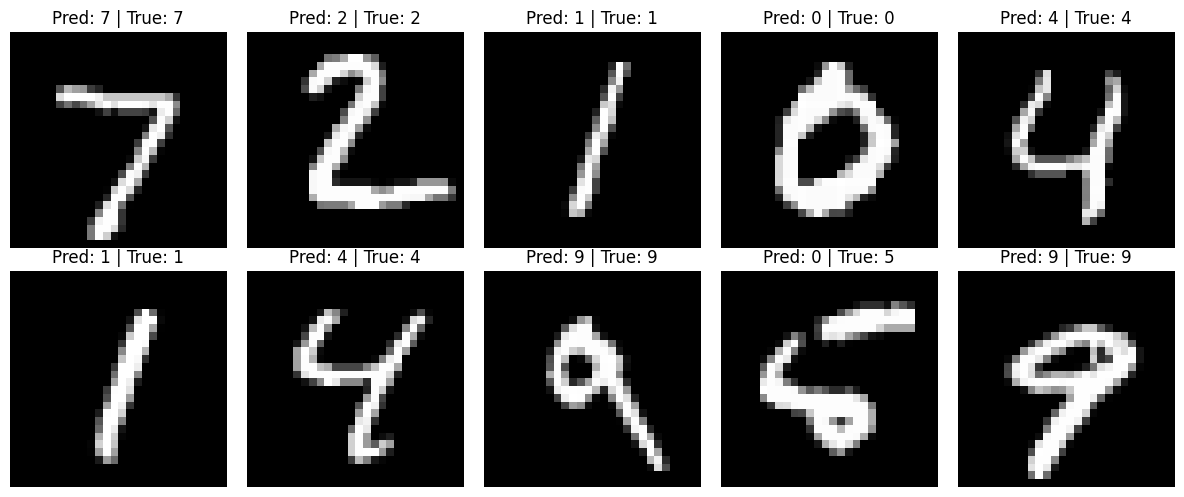

In [12]:
model.eval()
images, labels = next(iter(test_loader))
images_device = images.to(device)
with torch.no_grad():
    predictions = model(images_device).argmax(dim=1).cpu()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap='gray')
    pred = predictions[i].item()
    true = labels[i].item()
    ax.set_title(f'Pred: {pred} | True: {true}')
    ax.axis('off')
plt.tight_layout()
plt.show()